# 03 - SPC control charts

This notebook uses I-MR control charts to look for unusual readings and sustained
shifts in the SECOM sensors. Only the training period is used. Using the test
period to set limits or choose sensors would leak future information, so it stays locked.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from secom.data import load_secom, split_by_time
from secom.cleaning import fit_cleaning, apply_cleaning
from secom.spc import fit_limits, flag_outside, flag_runs

sensor_83 outside: 2 of 1096


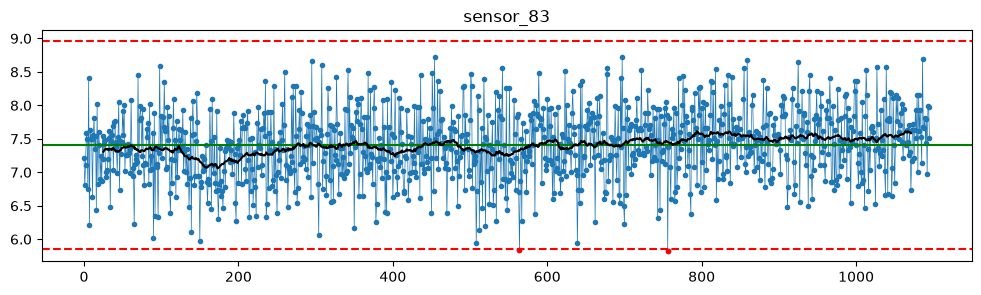

sensor_78 outside: 98 of 1096


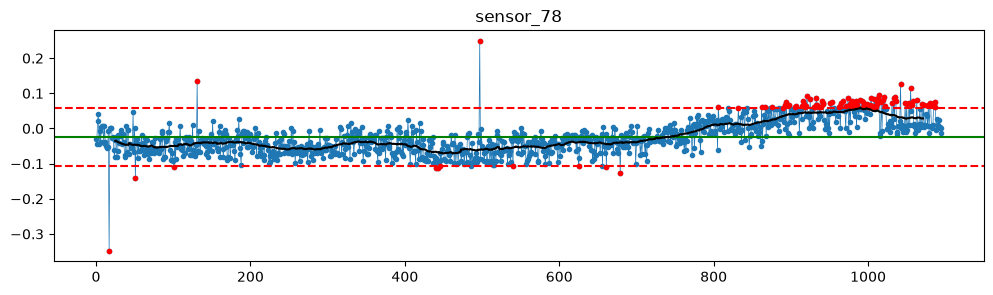

In [2]:
df = load_secom("../data/raw")
train, test = split_by_time(df)
rules = fit_cleaning(train)
train_clean = apply_cleaning(train, rules)

for sensor in ["sensor_83", "sensor_78"]:
    values = train_clean[sensor]
    limits = fit_limits(values)
    flagged = flag_outside(values, limits)

    print(sensor, "outside:", flagged.sum(), "of", len(values))

    plt.figure(figsize=(12, 3))
    plt.plot(values, marker=".", linewidth=0.5)
    plt.plot(values[flagged], "r.")          # red dots: outside the limits
    plt.axhline(limits["centre"], color="green")
    plt.axhline(limits["lower"], color="red", linestyle="--")
    plt.axhline(limits["upper"], color="red", linestyle="--")
    plt.plot(values.rolling(50, center=True).mean(), color="black")
    plt.title(sensor)
    plt.show()

**What this shows:** `sensor_83` is fairly stable: 2 of 1,096 points are outside the
limits. About 3 are expected by chance if the readings are roughly normal.

`sensor_78` is flat until about row 700, then rises, peaks around row 1000 and partly
falls back. With limits from all training rows, the shift is inside the baseline, so it
raises the centre line and 98 points are flagged. With limits from the first 700 rows,
157 are flagged, 151 of them after row 700, and the first alarm after row 700 comes at
row 780 instead of row 806.

**Assumption:** I chose row 700 after looking at the plot, so it is not a confirmed stable period.

In [3]:
values = train_clean["sensor_78"]

limits_all = fit_limits(values)
limits_flat = fit_limits(values.iloc[:700])     # only the first 700 rows

for name, limits in [("all train", limits_all), ("first 700", limits_flat)]:
    flagged = flag_outside(values, limits)
    print(name,
          "centre:", round(limits["centre"], 3),
          "upper:", round(limits["upper"], 3),
          "outside:", flagged.sum(),
          "after row 700:", flagged.iloc[700:].sum())
    print("   first alarm after row 700:", flagged.iloc[700:].idxmax())

all train centre: -0.024 upper: 0.059 outside: 98 after row 700: 86
   first alarm after row 700: 806
first 700 centre: -0.049 upper: 0.035 outside: 157 after row 700: 151
   first alarm after row 700: 780


In [4]:
rows = []
for sensor in rules["keep_cols"]:
    values = train_clean[sensor]
    limits = fit_limits(values)

    rows.append({
        "sensor": sensor,
        "outside": flag_outside(values, limits).sum(),
        "runs": flag_runs(values, limits).sum(),
    })

summary = pd.DataFrame(rows).set_index("sensor")
print(summary.describe().round(1))
print(summary.sort_values("outside", ascending=False).head(5))
print(summary.sort_values("runs", ascending=False).head(5))
print(summary.corr().round(2))

       outside    runs
count    416.0   416.0
mean      32.9   130.8
std       57.5   207.3
min        0.0     0.0
25%        8.0    20.0
50%       17.0    51.0
75%       33.0   119.2
max      449.0  1052.0
            outside  runs
sensor                   
sensor_405      449   611
sensor_539      387   581
sensor_267      373   568
sensor_588      323   388
sensor_587      317   368
            outside  runs
sensor                   
sensor_67         4  1052
sensor_340        4  1052
sensor_204        4  1052
sensor_249       12   983
sensor_114       11   983
         outside  runs
outside     1.00  0.44
runs        0.44  1.00


**What this shows:** the two rules catch different problems, and their top-5 lists share
no sensors. This does not mean they are opposites: across the 416 sensors the two counts
are positively correlated (about 0.44).

The top "runs" sensors have a few very large readings that pull the centre away from the
ordinary values, so nearly every point sits on one side. `sensor_67`, `sensor_340` and
`sensor_204` each have only 4 points outside but 1,052 run points. A high run count can
therefore mean a bad baseline rather than a real shift, so check the plot first.

mean:   22.577349543795624
median: 1.0125
above centre: 4 of 1096
457    7272.8283
634    6363.8013
275    6363.6566
466    3637.0928
709       1.8028
577       1.7850
Name: sensor_67, dtype: float64


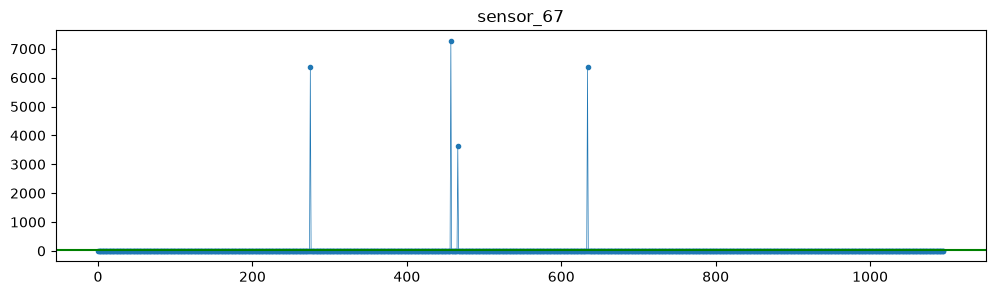

In [5]:
values = train_clean["sensor_67"]
limits = fit_limits(values)

print("mean:  ", values.mean())
print("median:", values.median())
print("above centre:", (values > limits["centre"]).sum(), "of", len(values))
print(values.nlargest(6))


plt.figure(figsize=(12, 3))
plt.plot(values, marker=".", linewidth=0.5)
plt.axhline(limits["centre"], color="green")
plt.title("sensor_67")
plt.show()

In [6]:
values = train_clean["sensor_67"]

# first try: limits from everything
limits_1 = fit_limits(values)
extreme = flag_outside(values, limits_1)

# second try: learn from the non-extreme points only
limits_2 = fit_limits(values[~extreme])

# apply BOTH to all the points, including the extreme ones
for name, limits in [("first", limits_1), ("refit", limits_2)]:
    print(name,
          "centre:", round(limits["centre"], 3),
          "outside:", flag_outside(values, limits).sum(),
          "runs:", flag_runs(values, limits).sum())

runs_2 = flag_runs(values, limits_2)
print("runs before row 880:", runs_2[:880].sum())
print("runs from row 880:", runs_2[880:].sum())
print("first limits:", round(limits_1["lower"], 1), round(limits_1["upper"], 1))
print("refit limits:", round(limits_2["lower"], 2), round(limits_2["upper"], 2))
late = values[880:][runs_2[880:]]
print("late run points below centre:", (late < limits_2["centre"]).sum(), "of", len(late))

first centre: 22.577 outside: 4 runs: 1052
refit centre: 1.014 outside: 42 runs: 58
runs before row 880: 18
runs from row 880: 40
first limits: -92.6 137.7
refit limits: 0.66 1.37
late run points below centre: 40 of 40


**What this shows:** four extreme points pulled the centre from about 1.01 to 22.58 and
widened the limits to -92.6 to 137.7. I left them out of the baseline but still checked
them against the new limits. After one refit, the limits are 0.66 to 1.37, points outside
rise from 4 to 42, and run points fall from 1,052 to 58.

Of those 58 run points, 40 are from row 880 onward and all are below the centre: a small
late downward slide that the outside rule does not show clearly.

**Assumption:** I removed the extremes once, based on their values alone. In a factory,
a point is removed only when a cause is found, and these sensors are anonymous. Repeated
refitting would tighten the limits further and flag more ordinary points.